# Analysis of the Behavior of the E-FCFW Algorithm

The Extended Fully-Corrective Frank-Wolfe (E-FCFW) algorithm decomposes a demand graph into a sparse weighted sum of
matchings. In Pennington et al. [1] and Liaqat et al. [2], single-layer QAOA supplies candidate matchings to this
classical algorithm by sampling a QUBO. In this notebook, I re-run every experiment of the two articles that does
not rely on quantum hardware or quantum circuit simulation. The single modification is the sampling subroutine:
wherever the articles sample a QUBO with **QAOA**, I sample it with **Goemans–Williamson with local search
(GW+LS)** [3], i.e., the QUBO is mapped to MaxCut, the SDP relaxation is solved, 1,000 random hyperplanes are drawn,
and each sample is refined by one-flip descent on the QUBO cost. As an additional classical reference, **MIP**
computes the 10 best matchings exactly. Simulated annealing (SA) [4], uniform random sampling, FCFW and greedy
Birkhoff decomposition (BKF) use the settings and sampling budgets of the articles, and every sampler supplies the
top $d=5$ distinct candidates to E-FCFW.

**Contents**

1. Background: the decomposition problem, E-FCFW and the partitioned QAOA pipeline
2. The Goemans–Williamson matching sampler
3. Experimental setup, validation and reproduction
4. Experiments of the 2025 article [1]
5. Experiments of the 2026 article [2]
6. Supplementary benchmark
7. Summary
8. References

## 1. Background

### 1.1 Minimum Birkhoff Decomposition

Let $G(V,E)$ be a weighted, undirected demand graph with $n$ nodes, represented by a symmetric doubly substochastic
matrix $D^*\in[0,1]^{n\times n}$ with zero diagonal; the entry $D^*_{uv}$ is the fraction of time during which nodes
$u$ and $v$ wish to be connected. A matching matrix belongs to

$$ \mathcal P := \{U\in\{0,1\}^{n\times n} \mid U=U^T,\ U\mathbf 1\preceq \mathbf 1,\ U_{ii}=0\ \forall i\}, $$

and the Minimum Birkhoff Decomposition (MBD) seeks the sparsest representation [1, 2]

$$ \min_{\alpha,\,P_l}\ \|\alpha\|_0 \quad\text{s.t.}\quad D^*=\sum_{l=1}^{m}\alpha_l P_l,\quad P_l\in\mathcal P,\quad
\alpha_l\ge 0,\quad \sum_{l}\alpha_l\le 1 . $$

The number of non-zero weights is the **decomposition length**. Sparse approximations are sought by minimizing the
normalized error $f(D)=\frac{1}{n^2}\|D-D^*\|_F^2$.

### 1.2 Extended Fully-Corrective Frank-Wolfe (E-FCFW)

At iteration $k$, the residual graph $G_k$ of $D^*-D_k$ is formed. The Frank-Wolfe linear minimization oracle
corresponds to a maximum-weight matching $M^{MW}$ on $G_k$ [1], computed with Edmonds' blossom algorithm [5]. E-FCFW [1]
augments this oracle with a sampling subroutine that generates $d$ candidate matchings $\mathcal M_{\text{sample}}$,
updates the active set $\mathcal M\leftarrow\mathcal M\cup\{M^{MW}\}\cup\mathcal M_{\text{sample}}$, and re-optimizes
the weights in a fully-corrective manner [6] under an explicit cardinality restriction:

$$ \min_{u\in\Delta^{|\mathcal M|}}\ \frac1{n^2}\Big\|D^*-\sum_{i=1}^{|\mathcal M|}u_iM_i\Big\|_F^2
\quad\text{s.t.}\quad \|u\|_0\le k+1 . $$

Matchings with zero weight are then removed from the active set. FCFW, the reference algorithm of [1], corresponds to
$d=0$, i.e., to the maximum-weight matching oracle alone.

### 1.3 Partitioned QAOA sampling

In [2], the residual graph is split by multi-way spectral partitioning [8] into subgraphs with at most $p_s$ edges.
Each subgraph is encoded as the QUBO

$$ C(x) = -\sum_{j\in E} w_jx_j + \lambda\sum_{j\in E}\sum_{k\in\Gamma(j)}x_jx_k ,\qquad \lambda = 0.2, $$

where $x_j=1$ selects edge $j$, $w_j$ is its residual weight, and $\Gamma(j)$ contains the edges sharing an endpoint
with $j$. Each QUBO is sampled with single-layer QAOA; the local samples are combined by batched Cartesian products,
greedy repair enforces matching feasibility (edges are accepted in descending order of residual weight if both
endpoints are unoccupied), and the top five distinct repaired matchings form $\mathcal M_{\text{sample}}$. The
2025 article [1] uses the same E-FCFW framework without partitioning and discards invalid samples instead of
repairing them.

## 2. The Goemans–Williamson matching sampler

**From QUBO to MaxCut.** Writing the QUBO as $C(x)=\sum_ih_ix_i+\sum_{i<j}J_{ij}x_ix_j$ and substituting
$x_i=(1+s_i)/2$ with $s_i\in\{-1,1\}$, the linear terms are absorbed by an auxiliary spin $s_0$, which is free by the
global spin-flip symmetry. With $a_i=h_i/2+\sum_jJ_{ij}/4$ and MaxCut weights $W_{0i}=2a_i$, $W_{ij}=J_{ij}/2$, one
obtains the exact identity

$$ C(x) = c - \sum_{i<j}W_{ij}\,[s_i\neq s_j] $$

for a constant $c$. Every cut of the $(N+1)$-node MaxCut instance therefore corresponds to exactly one bitstring, and
a larger cut means a lower QUBO cost.

**Sampling.** GW [3] relaxes each spin to a unit vector and solves the semidefinite program
$\max_{X\succeq0,\ X_{ii}=1}\sum_{i<j}W_{ij}(1-X_{ij})/2$; I solve it with CVXPY [12] and Clarabel [13]. The solution
$X=VV^T$ is rounded with random hyperplanes, $s_i=\operatorname{sign}(v_i^Tr)$ with $r\sim\mathcal N(0,I)$. Each
hyperplane yields one sample, so GW takes exactly the position of QAOA: one SDP per subgraph, and the samples enter
the repair, stitching and selection steps unchanged. Since the MaxCut weights can be negative, the 0.878 guarantee of
[3] does not formally apply, but the SDP value still bounds the QUBO minimum from below.

**Local search.** On these QUBOs the SDP solution has a very low rank, so the hyperplanes concentrate on a few distinct
cuts. GW+LS therefore refines every rounded sample by greedy one-flip descent on $C(x)$.

**Exact reference (MIP).** MIP solves the matching problem behind the QUBO exactly, with $x_j+x_k\le 1$ for every
conflicting pair, using HiGHS [14], and enumerates its 10 best solutions with no-good cuts [15].

**Implementation notes.** The maximum-weight matching is computed with rustworkx [11], a Rust implementation of
Edmonds' algorithm that returns the same matchings as NetworkX [16]; the cardinality-constrained weight update is
solved exactly by branch and bound over the supports, in place of the CPLEX solver used in [1].

## 3. Experimental setup, validation and reproduction

### 3.1 Instances

* **2025 experiments:** the original benchmark instances published with [1] (CC BY 4.0) [17], stored in
  `data/pennington2025`: 10 complete and 10 bipartite demand graphs per size, and the heavy-hex graphs of Fig. 10.
* **2026 experiments:** the demand matrices of [2] are not published. Following [2], the 120-node Heron-topology
  graph and the PEGASE-1354 demands are generated with the instance generator of [1, Sec. V.B.1]: $n$ random maximal
  matchings of the topology, Dirichlet weights, and their convex combination. The PEGASE-1354 topology [9] is taken
  from the IEEE PES Power Grid Library [10]; merging parallel branches yields the 1,354 nodes and 1,710 edges of [2].

### 3.2 Settings

| setting | 2025 experiments [1] | 2026 experiments [2] |
|---|---|---|
| partitioning | none | spectral, $p_s=50$ (20 and 80 in the PEGASE study) |
| penalty $\lambda$ | $0.2\sum_j w_j$ | $0.2$ |
| invalid samples | discarded | greedy repair |
| candidates per iteration | top $d=5$ valid | top $d=5$ distinct repaired |
| maximum-weight matching | from a parallel vanilla FCFW run | on $G_k$ |
| stopping criteria | $\varepsilon=10^{-6}$ (heavy-hex: 44 iterations) | $\varepsilon=10^{-6}$, relative improvement $\le10^{-3}$, 20 iterations |
| SA | 1,000 reads × 1,000 sweeps | 1,500 reads × 1,000 sweeps |
| uniform random sampling | 10,000 samples | 25,000 samples |
| **GW+LS** (replaces QAOA) | 1,000 hyperplanes + one-flip descent | 1,000 hyperplanes + one-flip descent |
| MIP (classical reference) | 10 best matchings | 10 best matchings per subgraph |

### 3.3 Validation

FCFW is deterministic, so its decomposition lengths can be compared instance by instance with Tables II–III of [1].
My FCFW reproduces them exactly for all small sizes (complete graphs with $n=6$, bipartite graphs with $n=6, 8$), and
for 45 of the 70 instances overall. On the larger instances the trajectories diverge, which I attribute to the
CPLEX-based weight update of [1] (degenerate optima and numerical tolerances); the numbers of the two
implementations are therefore not directly comparable on those instances.

### 3.4 Reproduction

The results shown below are produced by the following scripts of the accompanying repository and stored in
`results/`; this notebook only loads them and redraws the figures.

```bash
python scripts/replicate_2025.py fig3        # also: fig6, complete, bipartite, heavyhex
python scripts/replicate_2026.py fig3a       # also: fig3a_full, fig3c, fig2a, fig4
python scripts/compare_qubo_solvers.py       # choice of the classical sampler (Sec. 4.7)
python scripts/run_benchmarks.py benchmark --instances 3 --timeout 60    # Sec. 6
```

Every run is limited by a wall-clock timeout. The next cell loads the code and reports the software versions used.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
sys.path.insert(0, str(Path.cwd().parent / "scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from efcfw import paper_figures as pf
from efcfw.results_io import load_runs
from efcfw.instances import load_instance
import replicate_2025 as r25
import replicate_2026 as r26
%matplotlib inline

R25, R26 = Path.cwd().parent / "results" / "2025", Path.cwd().parent / "results" / "2026"
pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 100

def available(path):
    if not path.exists():
        print(f"missing: {path.name} (run the replication script first)")
        return False
    return True

In [2]:
import platform
from importlib.metadata import version
print("Python", platform.python_version())
print(", ".join(f"{p} {version(p)}" for p in ["numpy", "scipy", "networkx", "rustworkx", "cvxpy", "clarabel",
                                             "scikit-learn", "pandas", "matplotlib"]))

Python 3.14.0
numpy 2.5.4, scipy 1.18.1, networkx 3.7, rustworkx 0.18.1, cvxpy 1.9.3, clarabel 0.11.1, scikit-learn 1.9.1, pandas 3.0.6, matplotlib 3.11.2


### 3.5 Overview of the experiments

| article | experiment | section | omitted (quantum only) |
|---|---|---|---|
| 2025 [1] | Birkhoff baseline, bipartite graphs (Fig. 3) | 4.1 | – |
| 2025 [1] | top five sampled matchings (Fig. 6) | 4.2 | – |
| 2025 [1] | complete graphs, 10 instances per size (Fig. 7, Table II, Fig. 9) | 4.3, 4.4 | – |
| 2025 [1] | bipartite graphs, 10 instances per size (Fig. 8, Table III) | 4.5 | – |
| 2025 [1] | heavy-hex graphs with 50/70/100 nodes (Figs. 10, 11) | 4.6 | QAOA on IBM Kingston, MPS simulation, Table I |
| 2026 [2] | synthetic Heron graph, 120 nodes and 132 edges (Fig. 2(a)) | 5.1 | Fig. 2(b) MPS bond dimension, QAOA hardware |
| 2026 [2] | PEGASE-1354, partition bounds, baselines and repair (Figs. 3(a), 3(c)) | 5.2 | Fig. 3(b) hardware versus simulation |
| 2026 [2] | PEGASE-1354 partition layout (Fig. 4) | 5.3 | Fig. 5 circuit packing, Fig. 6 QAOA landscape, Table I |

## 4. Experiments of the 2025 article [1]

All runs in this section use the 2025 setting of Sec. 3.2 on the original instances of [1].

### 4.1 Greedy Birkhoff baseline (Fig. 3 of [1])

The article illustrates that Birkhoff+ [7] requires considerably more matchings than the $n$ matchings used to create
the graph. Since Birkhoff+ is not reimplemented here, I use the classical greedy Birkhoff decomposition with
maximum-weight perfect matchings on instances of the same type: $K_{n,n}$ with $n$ planted perfect matchings.

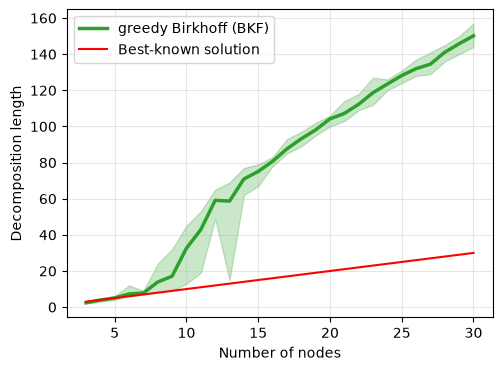

In [3]:
if available(R25 / "fig3_birkhoff.csv"):
    pf.fig3_birkhoff(pd.read_csv(R25 / "fig3_birkhoff.csv"));

### 4.2 First five sampled matchings (Fig. 6 of [1])

Complete graph with $n=8$ (instance 1), first iteration. The top row shows the maximum-weight matching found by
NetworkX [16] (Edmonds' algorithm [5]); the rows below show the five highest-weight *valid* matchings sampled with GW
and SA. In the article, the 2nd–5th matchings sampled with QAOA had lower weight than, and differed from, those of SA.
The MIP row shows the exact five best matchings for comparison.

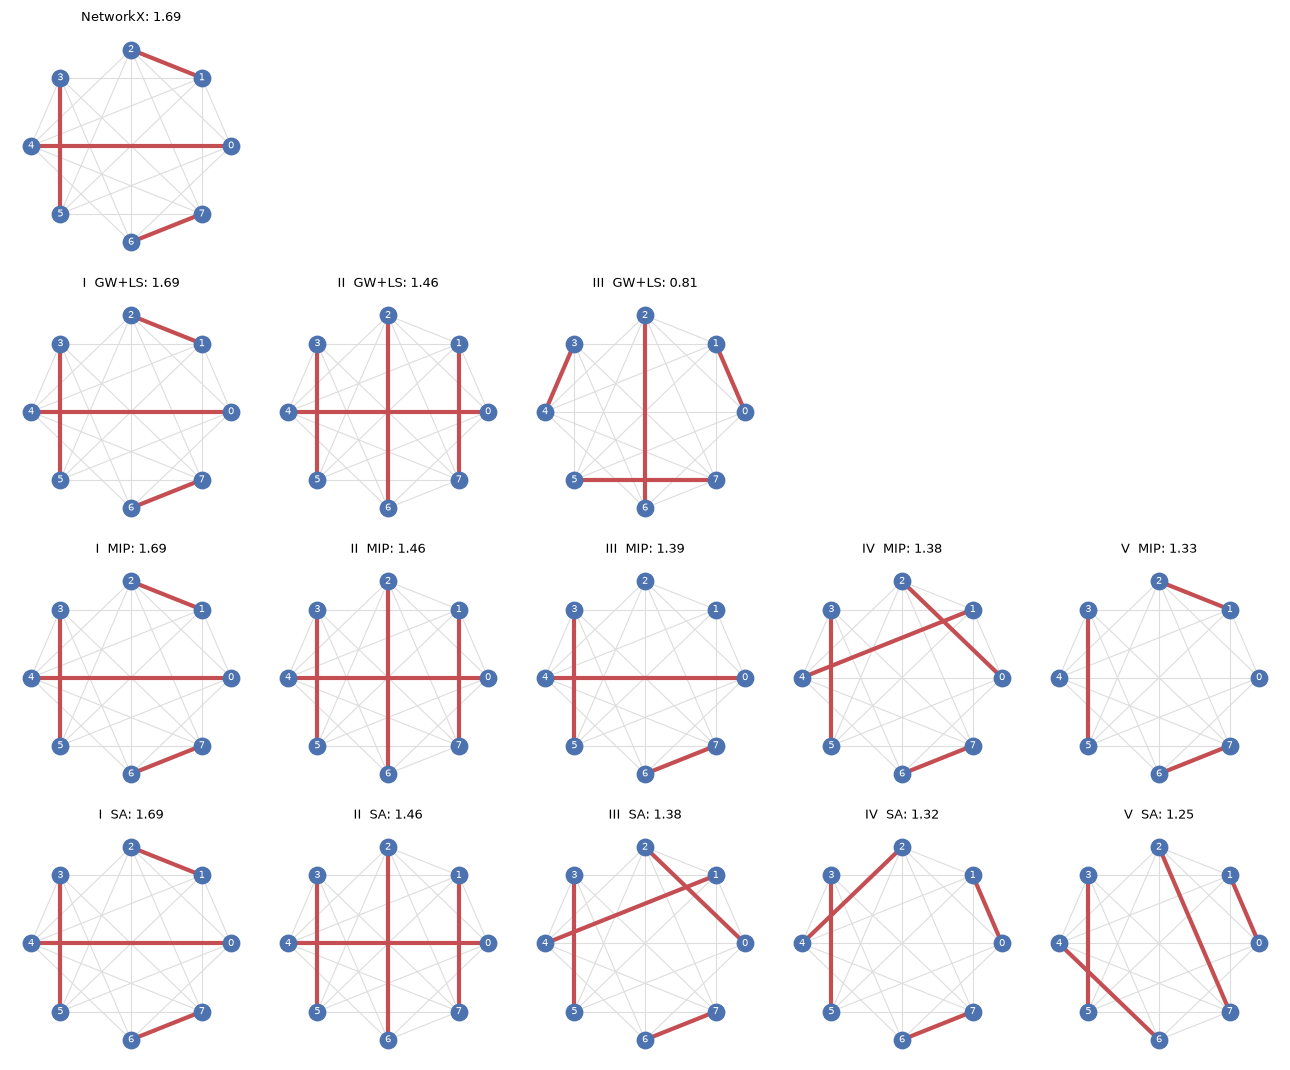

In [4]:
if available(R25 / "fig6.json"):
    payload = pd.read_json(R25 / "fig6.json", typ="series")
    D = load_instance("complete", 8, 1).demand
    rows = {k: [(e, w) for e, w in v] for k, v in payload["rows"].items()}
    pf.fig6_top_matchings(D, payload["mw"], rows, payload["mw_weight"]);

### 4.3 Complete graphs (Fig. 7 and Table II of [1])

Median decomposition length over 10 instances for $n=6,\dots,9$; the error bars represent the minimum and maximum over
the instances. Lower is better. Averages reported in [1] for $n=9$: FCFW 17.2, random sampling 15.7, QAOA 13.6,
SA 15.1.

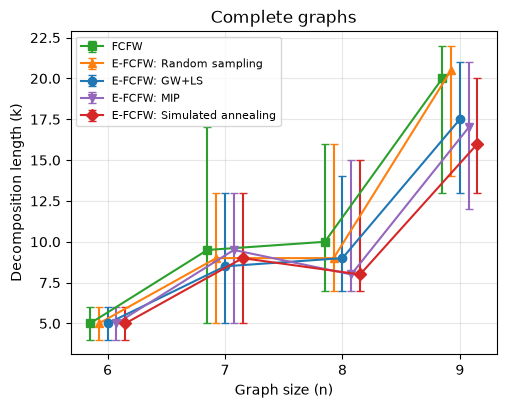

,FCFW,E-FCFW: Random sampling,E-FCFW: GW+LS,E-FCFW: MIP,E-FCFW: Simulated annealing
n,,,,,
6,4.8,4.8,4.8,4.8,4.8
7,9.9,9.3,8.8,9.4,9.2
8,10.4,9.7,9.4,8.9,9.4
9,18.8,19.3,17.5,16.9,16.2


In [5]:
methods = list(r25.LABELS.values())
if available(R25 / "complete.json"):
    runs_c = load_runs(R25 / "complete.json")
    table_c = r25.runs_table(runs_c)
    pf.fig7_median_lengths(table_c, "Complete graphs", methods)
    plt.show()
    display(table_c.groupby(["n", "method"]).length.mean().unstack()[methods].rename_axis(columns=None)
            .style.format("{:.1f}").set_caption("average decomposition length (Table II, 'Average' rows)"))
    display(pf.table_lengths_errors(table_c, methods).style
            .format("{:.0f}", subset=pd.IndexSlice[:, "Decomposition length"])
            .format("{:.1e}", subset=pd.IndexSlice[:, "Decomposition approximation"])
            .set_caption("Table II: per-instance lengths and errors"))

### 4.4 Matching overlap (Fig. 9 of [1])

Complete graph with $n=9$, instance 2. Each cell indicates the number of edges shared by two matchings of the final
decomposition. The article observed lower overlap, i.e., greater diversity, for the shortest decomposition.

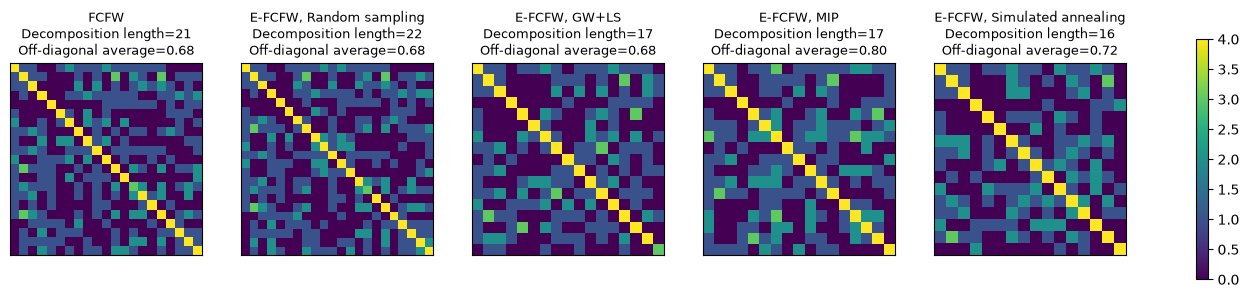

In [6]:
if available(R25 / "complete.json"):
    D9 = load_instance("complete", 9, 2).demand
    chosen = {r.method.replace("E-FCFW: ", "E-FCFW, "): r for r in runs_c if r.instance == "complete-9-2"}
    pf.fig9_overlap(D9, chosen);

### 4.5 Bipartite graphs (Fig. 8 and Table III of [1])

Median decomposition length over 10 instances for $n=6,8,10$, as in Sec. 4.3.

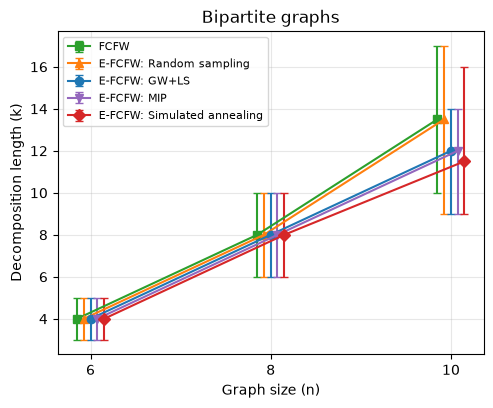

,FCFW,E-FCFW: Random sampling,E-FCFW: GW+LS,E-FCFW: MIP,E-FCFW: Simulated annealing
n,,,,,
6,4.0,4.0,4.0,4.0,4.0
8,7.7,7.8,7.7,7.8,7.6
10,13.5,13.0,11.5,11.7,11.7


In [7]:
if available(R25 / "bipartite.json"):
    runs_b = load_runs(R25 / "bipartite.json")
    table_b = r25.runs_table(runs_b)
    pf.fig7_median_lengths(table_b, "Bipartite graphs", methods)
    plt.show()
    display(table_b.groupby(["n", "method"]).length.mean().unstack()[methods].rename_axis(columns=None)
            .style.format("{:.1f}").set_caption("average decomposition length (Table III)"))

### 4.6 Heavy-hex graphs (Figs. 10 and 11 of [1])

Decomposition error versus decomposition length on the nine heavy-hex graphs with 50, 70 and 100 nodes and the edge
counts of the article (53/54/52, 76, 110/111/110). In the article, QAOA was executed on IBM Kingston and with MPS
circuit simulation; here GW takes its place. As in the article, none of the uniformly sampled bitstrings correspond to
valid matchings at this scale, so the random-sampling curve coincides with FCFW.

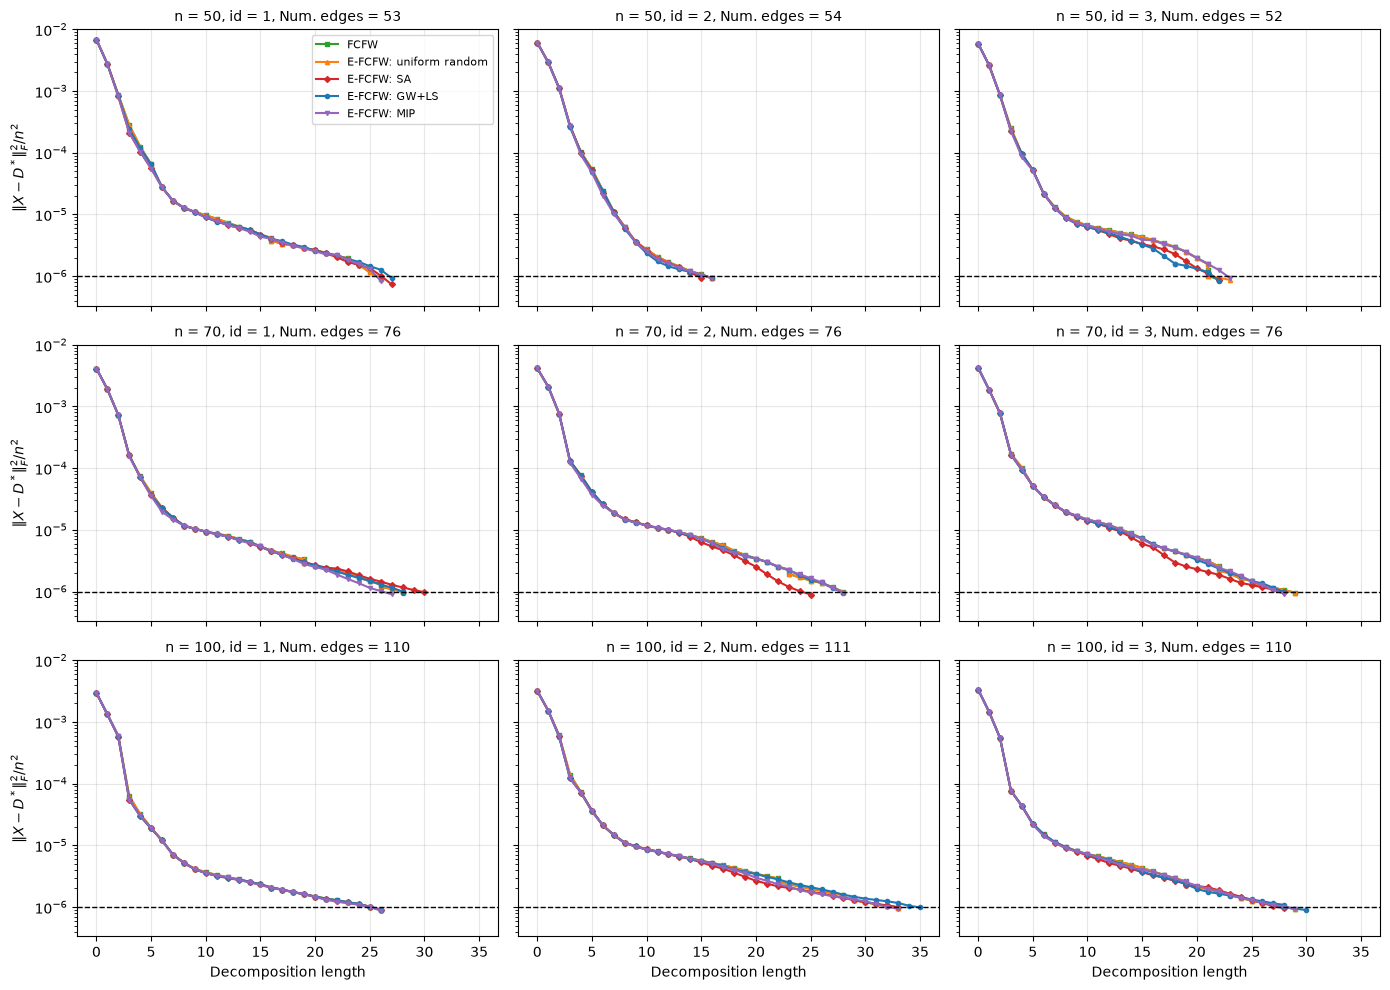

method,FCFW,E-FCFW: uniform random,E-FCFW: SA,E-FCFW: GW+LS,E-FCFW: MIP
instance,,,,,
heavy_hex-50-1,9.07e-07,9.07e-07,7.35e-07,9.35e-07,8.42e-07
heavy_hex-50-2,9.20e-07,9.20e-07,9.45e-07,9.20e-07,9.20e-07
heavy_hex-50-3,8.78e-07,8.73e-07,8.74e-07,8.41e-07,9.43e-07
heavy_hex-70-1,9.93e-07,9.93e-07,9.77e-07,9.35e-07,9.06e-07
heavy_hex-70-2,9.88e-07,9.88e-07,8.97e-07,9.50e-07,9.66e-07
heavy_hex-70-3,9.57e-07,9.57e-07,9.77e-07,9.82e-07,9.18e-07
heavy_hex-100-1,9.12e-07,9.12e-07,8.99e-07,8.87e-07,8.75e-07
heavy_hex-100-2,9.79e-07,9.79e-07,9.98e-07,9.87e-07,9.37e-07
heavy_hex-100-3,9.22e-07,9.22e-07,9.58e-07,8.92e-07,9.44e-07


In [8]:
if available(R25 / "heavyhex.json"):
    runs_h = load_runs(R25 / "heavyhex.json")
    instances = [(f"heavy_hex-{n}-{i}", e) for n, i, e in r25.HEAVY_HEX]
    pf.fig10_heavy_hex(runs_h, instances, list(r25.LABELS_FIG10.values()))
    plt.show()
    display(r25.runs_table(runs_h).pivot_table(index="instance", columns="method", values="cost", sort=False)
            .style.format("{:.2e}").set_caption("final error"))

**Matching weights in the final decomposition** ($n=50$, instance 1; Fig. 11 of [1]). The weight of a matching $M$ is
$\sum_{e\in M} D^*_e$.

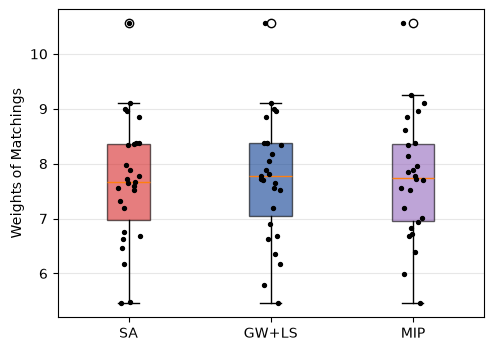

In [9]:
if available(R25 / "heavyhex.json"):
    D50 = load_instance("heavy_hex", 50, 1).demand
    chosen = {r.method.replace("E-FCFW: ", ""): r for r in runs_h
              if r.instance == "heavy_hex-50-1" and r.method in ("E-FCFW: GW+LS", "E-FCFW: MIP", "E-FCFW: SA")}
    pf.fig11_matching_weights(D50, chosen);

### 4.7 Choice of the classical sampler

I run the same E-FCFW pipeline (2025 setting) on the 30 original instances on which the methods differ most
(complete graphs with $n=8,9$, bipartite graphs with $n=10$), with different QUBO solvers in the sampling subroutine.
The table reports the mean decomposition length (lower is better) and the mean time spent in the sampler per run.
Plain GW improves with a larger sample; a one-flip local search yields the same improvement at negligible cost; and
the exact list of the best matchings (MIP) performs on par with simulated annealing at a fraction of its runtime.

In [10]:
f = Path.cwd().parent / "results" / "qubo_solvers" / "summary.csv"
if available(f):
    display(pd.read_csv(f, header=[0, 1], index_col=0).round(2))

kind                      complete       bipartite        mean length  \
n                                8     9        10 Unnamed: 4_level_1   
solver                                                                  
FCFW                          10.4  18.8      13.5              14.23   
Random (10,000)                9.7  19.3      13.0              14.00   
SA (1,000 reads)               9.4  16.2      11.7              12.43   
GW (50)                        9.4  18.7      12.5              13.53   
GW (10,000)                    9.2  17.3      11.9              12.80   
GW + local search (50)         9.2  17.3      11.6              12.70   
GW + local search (1,000)      9.4  17.5      11.5              12.80   
MIP: 10 best matchings         8.9  16.9      11.7              12.50   

kind                      mean sampler time [s]  
n                            Unnamed: 5_level_1  
solver                                           
FCFW                                       0.00  
Random (10,000)                            0.26  
SA (1,000 reads)                           8.11  
GW (50)                                    0.20  
GW (10,000)                                0.40  
GW + local search (50)                     0.17  
GW + local search (1,000)                  0.19  
MIP: 10 best matchings                     1.24

## 5. Experiments of the 2026 article [2]

All runs in this section use the 2026 setting of Sec. 3.2.

### 5.1 Synthetic Heron-topology graph with 120 nodes and 132 edges (Fig. 2(a) of [2])

The article curves "QAOA Sim" and "QAOA Sim ($p_s$=50)" are replaced by "GW+LS" and "GW+LS ($p_s$=50)", and MIP is
added. The hardware curves and Fig. 2(b) (MPS bond dimension) concern quantum execution and are omitted.

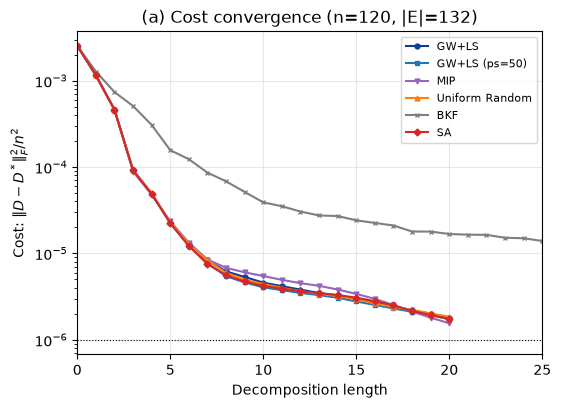

,decomposition length,final cost,runtime [s],stop
method,,,,
GW+LS,20,1.803e-06,301.230,max iterations
GW+LS (ps=50),20,1.735e-06,13.200,max iterations
MIP,20,1.555e-06,5.690,max iterations
Uniform Random,20,1.852e-06,9.979,max iterations
BKF,25,1.394e-05,0.014,max length
SA,20,1.736e-06,87.448,max iterations


In [11]:
if available(R26 / "fig2a.json"):
    runs = load_runs(R26 / "fig2a.json")
    pf.fig_convergence(runs, [s[0] for s in r26.FIG2A], "(a) Cost convergence (n=120, |E|=132)")
    plt.show()
    display(pd.DataFrame([{"method": r.method, "decomposition length": r.decomposition_length, "final cost": r.cost,
                           "runtime [s]": r.runtime_s, "stop": r.stop_reason} for r in runs]).set_index("method"))

### 5.2 PEGASE-1354 (Figs. 3(a) and 3(c) of [2])

(a) Partition bounds $p_s\in\{20,50,80\}$ for GW, compared with SA ($p_s$=50, 80) and uniform random sampling
($p_s$=50), all with feasibility repair. (c) GW with and without greedy repair; without repair, invalid candidates
are discarded. Panel (b) of the article (hardware versus simulation, spatial circuit packing) concerns quantum
execution and is omitted.

On the generated PEGASE demand, every method reaches $\varepsilon=10^{-6}$ after exactly 10 iterations, so all curves
in (a) and (c) stop at the same decomposition length. Panel (a') therefore repeats (a) without the tolerance
criterion, i.e., for all 20 iterations, so that the samplers can be distinguished.

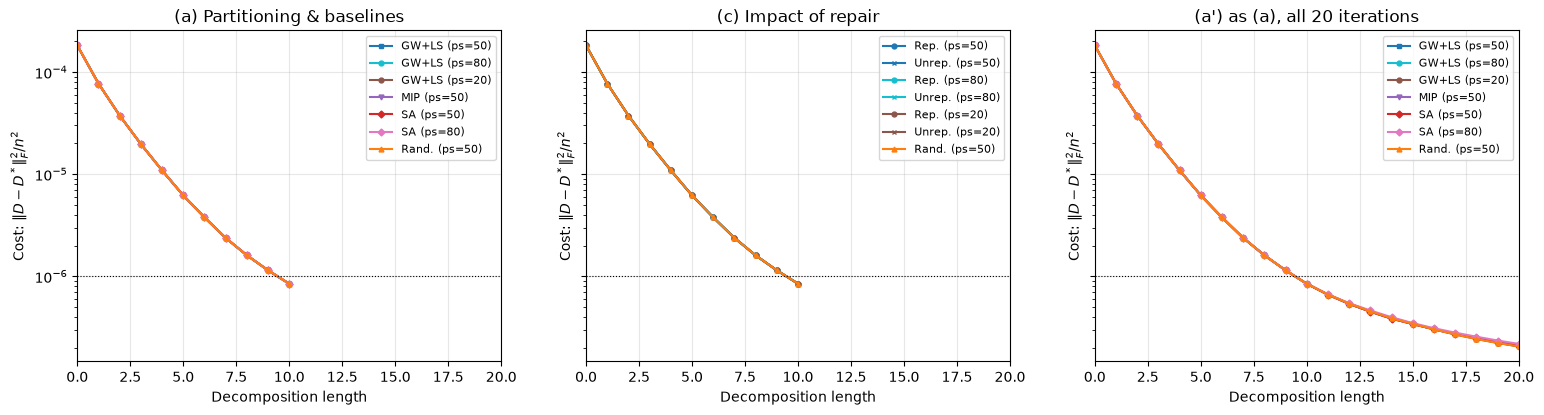

decomposition length  final cost  runtime [s]  \
panel      method                                                          
fig3a      GW+LS (ps=50)                     10   8.446e-07       96.754   
           GW+LS (ps=80)                     10   8.440e-07      247.159   
           GW+LS (ps=20)                     10   8.449e-07       29.799   
           MIP (ps=50)                       10   8.427e-07       70.177   
           SA (ps=50)                        10   8.427e-07      487.507   
           SA (ps=80)                        10   8.446e-07      504.451   
           Rand. (ps=50)                     10   8.449e-07       76.974   
fig3c      Rep. (ps=50)                      10   8.446e-07      105.599   
           Unrep. (ps=50)                    10   8.446e-07      104.901   
           Rep. (ps=80)                      10   8.440e-07      276.321   
           Unrep. (ps=80)                    10   8.440e-07      274.704   
           Rep. (ps=20)                      10   8.449e-07       30.170   
           Unrep. (ps=20)                    10   8.449e-07       30.458   
           Rand. (ps=50)                     10   8.449e-07       82.025   
fig3a_full GW+LS (ps=50)                     20   2.104e-07      188.610   
           GW+LS (ps=80)                     20   2.059e-07      469.867   
           GW+LS (ps=20)                     20   2.051e-07       78.827   
           MIP (ps=50)                       20   2.071e-07      145.383   
           SA (ps=50)                        20   2.073e-07      924.602   
           SA (ps=80)                        20   2.172e-07      968.554   
           Rand. (ps=50)                     20   2.051e-07      169.080   

                                     stop  
panel      method                          
fig3a      GW+LS (ps=50)        tolerance  
           GW+LS (ps=80)        tolerance  
           GW+LS (ps=20)        tolerance  
           MIP (ps=50)          tolerance  
           SA (ps=50)           tolerance  
           SA (ps=80)           tolerance  
           Rand. (ps=50)        tolerance  
fig3c      Rep. (ps=50)         tolerance  
           Unrep. (ps=50)       tolerance  
           Rep. (ps=80)         tolerance  
           Unrep. (ps=80)       tolerance  
           Rep. (ps=20)         tolerance  
           Unrep. (ps=20)       tolerance  
           Rand. (ps=50)        tolerance  
fig3a_full GW+LS (ps=50)   max iterations  
           GW+LS (ps=80)   max iterations  
           GW+LS (ps=20)   max iterations  
           MIP (ps=50)     max iterations  
           SA (ps=50)      max iterations  
           SA (ps=80)      max iterations  
           Rand. (ps=50)   max iterations

In [12]:
panels = [(f, specs, title) for f, specs, title in [("fig3a", r26.FIG3A, "(a) Partitioning & baselines"),
                                                    ("fig3c", r26.FIG3C, "(c) Impact of repair"),
                                                    ("fig3a_full", r26.FIG3A, "(a') as (a), all 20 iterations")]
          if available(R26 / f"{f}.json")]
if panels:
    fig, axes = plt.subplots(1, len(panels), figsize=(6.2 * len(panels), 4.3), sharey=True, squeeze=False)
    rows = []
    for ax, (f, specs, title) in zip(axes[0], panels):
        runs = load_runs(R26 / f"{f}.json")
        pf.fig_convergence(runs, [s[0] for s in specs], title, ax=ax, max_length=20)
        rows += [{"panel": f, "method": r.method, "decomposition length": r.decomposition_length,
                  "final cost": r.cost, "runtime [s]": r.runtime_s, "stop": r.stop_reason} for r in runs]
    plt.show()
    display(pd.DataFrame(rows).set_index(["panel", "method"]))

### 5.3 PEGASE-1354 partitioned with $p_s=50$ (Fig. 4 of [2])

The article reports 41 subgraphs. Colors distinguish neighboring partitions, and dashed red lines are cut edges.

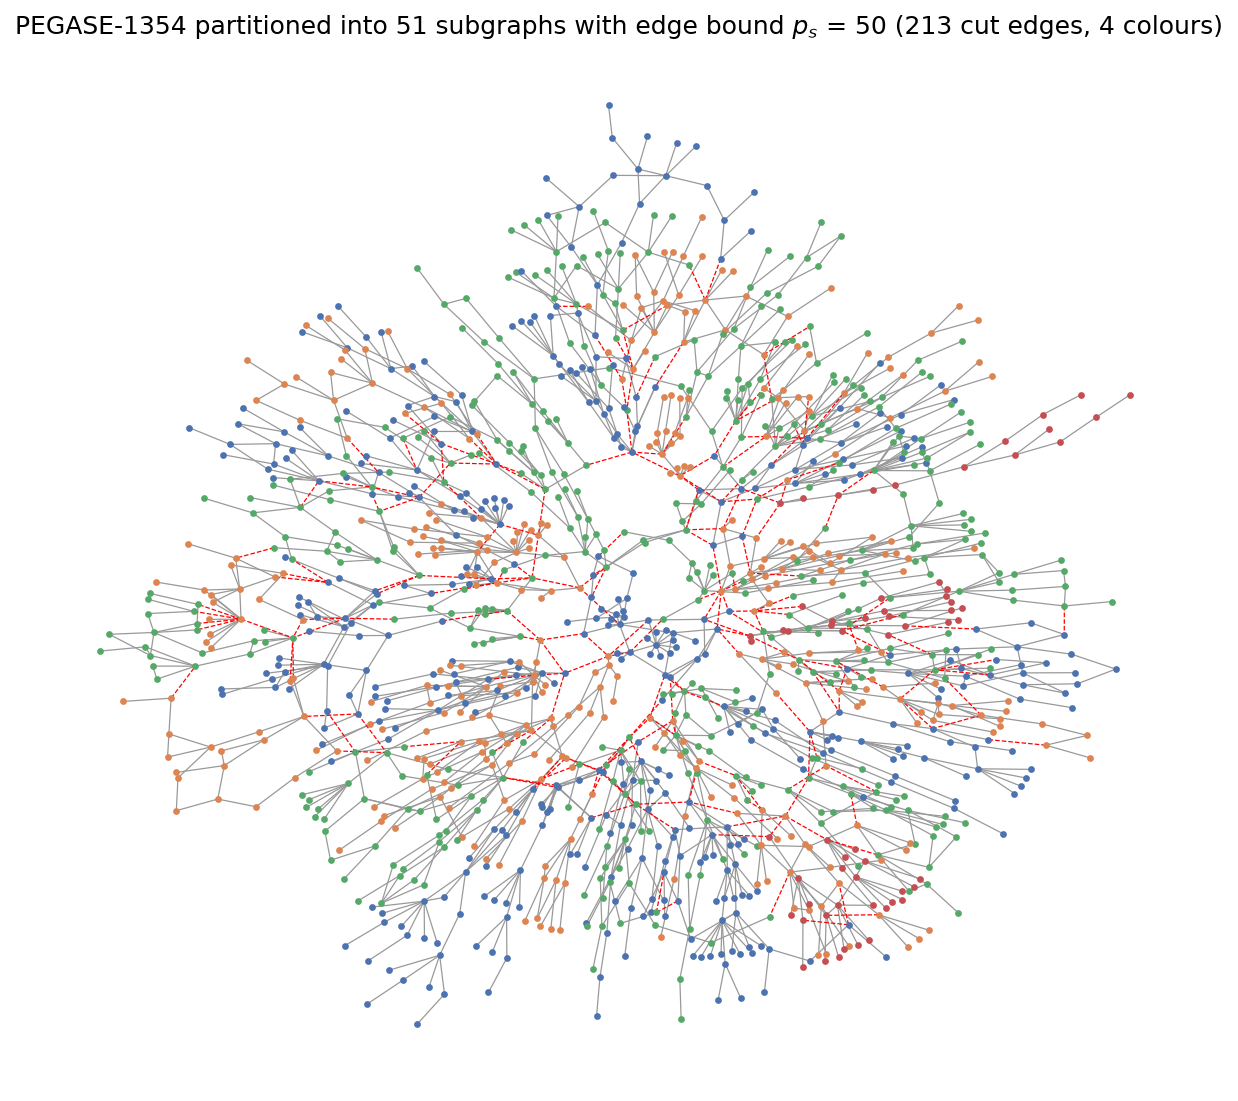

In [13]:
if available(R26 / "fig4_pegase_partitions.png"):
    display(Image(filename=str(R26 / "fig4_pegase_partitions.png"), width=800))

## 6. Supplementary benchmark

To compare the samplers on instances on which none of them is trivially sufficient, I run the 2026 pipeline on 18
graphs: heavy-hex graphs and connected subgraphs of PEGASE-1354 with 40, 60 and 80 nodes, three of each, all limited
to 20 iterations and 60 seconds per run. FCFW (no sampling subroutine) and BKF serve as references. Following common
practice in optimization benchmarking [18], the results are summarized by the shifted geometric mean

$$ \operatorname{SGM}_s(f_1,\dots,f_N)=\exp\Big(\tfrac1N\sum_{i=1}^N \ln(f_i+s)\Big)-s , $$

with $s=10^{-7}$ for the normalized error $f$ (final, and the best error with at most $L$ matchings) and $s=1$ s for
the runtime.

,instances,SGM objective (final),relative to best,SGM objective @ length 10,SGM objective @ length 20,SGM runtime [s],timeouts
method,,,,,,,
GW+LS,18,3.10e-06,1.00,1.51e-05,3.10e-06,2.8,0
MIP,18,3.33e-06,1.07,1.69e-05,3.33e-06,3.29,0
SA,18,3.10e-06,1.00,1.67e-05,3.10e-06,31.6,0
Random,18,4.08e-06,1.32,1.88e-05,4.08e-06,3.91,0
BKF,18,1.44e-05,4.64,1.06e-04,1.44e-05,0.00266,0
FCFW,18,3.14e-06,1.02,1.37e-05,3.14e-06,0.00507,0


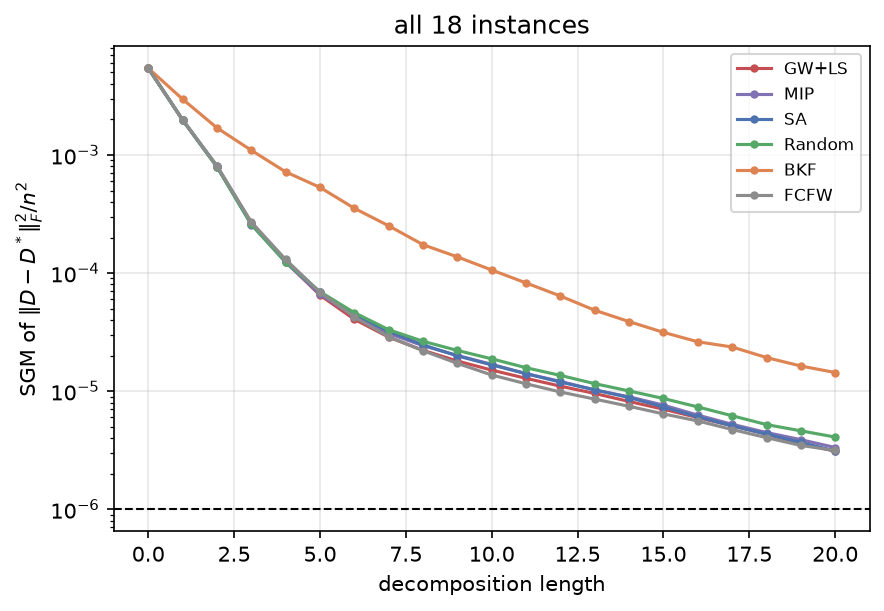

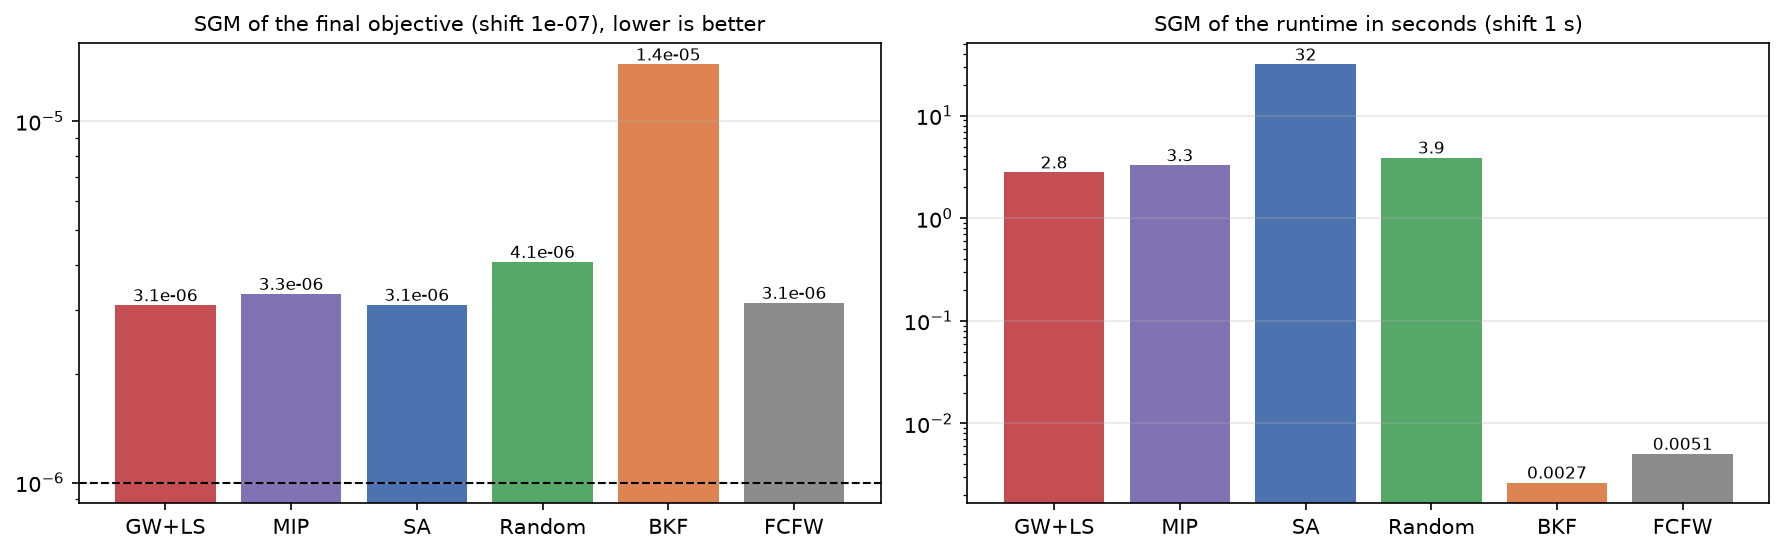

In [14]:
RB = Path.cwd().parent / "results" / "benchmark"
if available(RB / "benchmark_summary.csv"):
    summary = pd.read_csv(RB / "benchmark_summary.csv", index_col=0)
    display(summary[["instances", "SGM objective (final)", "relative to best", "SGM objective @ length 10",
                     "SGM objective @ length 20", "SGM runtime [s]", "timeouts"]]
            .style.format({"SGM objective (final)": "{:.2e}", "relative to best": "{:.2f}",
                           "SGM objective @ length 10": "{:.2e}", "SGM objective @ length 20": "{:.2e}",
                           "SGM runtime [s]": "{:.3g}"}))
    for name in ["benchmark_sgm_convergence.png", "benchmark_sgm_bars.png"]:
        display(Image(filename=str(RB / name), width=760))

## 7. Summary

In my classical re-runs, the deterministic components of the pipeline (the global maximum-weight matching, greedy
feasibility repair and the fully-corrective weight update) account for nearly all of the decomposition quality.
With these in place, the choice of QUBO sampler has only a small effect: Goemans–Williamson, simulated annealing
and an exact solver perform within a few percent of each other, and FCFW without any sampler is within 2% of the
best method on my benchmark. Greedy repair, in particular, turns even uniformly random bitstrings into valid
candidates of reasonably high weight. The instances on which a sampler, quantum or classical, can make a decisive
difference therefore appear to be those where the maximum-weight matching alone falls short. Identifying such
instances seems to me the most promising next step.

## 8. References

[1] G. Pennington, N. Mohseni, O. Wallis, F. Schiavello, S. Mensa, C. O'Meara, G. Cortiana, and V. Valls,
"Boosting sparsity in graph decompositions with QAOA sampling," arXiv:2509.10657 (2025).
https://arxiv.org/abs/2509.10657

[2] A. Liaqat, A. Darwish, S. DiAdamo, D. Holme, K. McDowall, E. Sahin, N. Mohseni, G. Cortiana, and C. O'Meara,
"Scaling quantum optimization to the thousand-qubit scale with distributed quantum sampling," arXiv:2610.10772 (2026).
https://arxiv.org/abs/2610.10772

[3] M. X. Goemans and D. P. Williamson, "Improved approximation algorithms for maximum cut and satisfiability
problems using semidefinite programming," *Journal of the ACM* **42**, 1115–1145 (1995).
https://doi.org/10.1145/227683.227684

[4] S. Kirkpatrick, C. D. Gelatt Jr., and M. P. Vecchi, "Optimization by simulated annealing," *Science* **220**,
671–680 (1983). https://doi.org/10.1126/science.220.4598.671

[5] J. Edmonds, "Paths, trees, and flowers," *Canadian Journal of Mathematics* **17**, 449–467 (1965).
https://doi.org/10.4153/CJM-1965-045-4

[6] S. Lacoste-Julien and M. Jaggi, "On the global linear convergence of Frank-Wolfe optimization variants,"
*Advances in Neural Information Processing Systems* **28** (2015).

[7] V. Valls, G. Iosifidis, and L. Tassiulas, "Birkhoff's decomposition revisited: Sparse scheduling for high-speed
circuit switches," *IEEE/ACM Transactions on Networking* **29**, 2399–2412 (2021).

[8] A. Y. Ng, M. I. Jordan, and Y. Weiss, "On spectral clustering: Analysis and an algorithm," *Advances in Neural
Information Processing Systems* **14** (2001).

[9] S. Fliscounakis, P. Panciatici, F. Capitanescu, and L. Wehenkel, "Contingency ranking with respect to overloads in
very large power systems taking into account uncertainty, preventive, and corrective actions," *IEEE Transactions on
Power Systems* **28**, 4909–4917 (2013). https://doi.org/10.1109/TPWRS.2013.2251015

[10] S. Babaeinejadsarookolaee et al., "The power grid library for benchmarking AC optimal power flow algorithms,"
arXiv:1908.02788 (2019). Case file `pglib_opf_case1354_pegase.m`, https://github.com/power-grid-lib/pglib-opf

[11] M. J. Treinish et al., "rustworkx: A high-performance graph library for Python," *Journal of Open Source
Software* **7**, 3968 (2022). https://doi.org/10.21105/joss.03968

[12] S. Diamond and S. Boyd, "CVXPY: A Python-embedded modeling language for convex optimization," *Journal of
Machine Learning Research* **17**, 1–5 (2016).

[13] P. J. Goulart and Y. Chen, "Clarabel: An interior-point solver for conic programs with quadratic objectives,"
arXiv:2405.12762 (2024).

[14] Q. Huangfu and J. A. J. Hall, "Parallelizing the dual revised simplex method," *Mathematical Programming
Computation* **10**, 119–142 (2018).

[15] E. Balas and R. Jeroslow, "Canonical cuts on the unit hypercube," *SIAM Journal on Applied Mathematics* **23**,
61–69 (1972).

[16] A. A. Hagberg, D. A. Schult, and P. J. Swart, "Exploring network structure, dynamics, and function using
NetworkX," *Proceedings of the 7th Python in Science Conference*, 11–15 (2008).

[17] G. Pennington, N. Mohseni, O. Wallis, and V. Valls, "QAOA – Graph Decomposition" (2025), benchmark instances
(CC BY 4.0), https://github.com/victor-ibm/QAOA-graph-decomposition

[18] T. Achterberg, "Constraint integer programming," PhD thesis, Technische Universität Berlin (2007).